In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Define the dataset file paths

data_path = Path("../data")

train_file = data_path / "deliveries_train.csv"
test_file = data_path / "deliveries_test.csv"

# Load the CSV files

train = pd.read_csv(train_file)
test = pd.read_csv(test_file)

print("Datasets loaded successfully!")

# Display dataset dimensions

print("\nTraining dataset shape:", train.shape)
print("Testing dataset shape:", test.shape)

Datasets loaded successfully!

Training dataset shape: (8000, 13)
Testing dataset shape: (2000, 12)


In [ ]:
# Display the first five rows of the training dataset

print("TRAINING DATASET")
display(train.head())

# Display the first five rows of the testing dataset

print("TESTING DATASET")
display(test.head())

In [7]:
# 1. Check column names
print("TRAINING COLUMNS:")
print(train.columns.tolist())

# 2. Check data types
print("\nTRAINING DATA TYPES:")
print(train.dtypes)

# 3. Check missing values
print("\nMISSING VALUES IN TRAINING DATA:")
print(train.isnull().sum())

print("\nMISSING VALUES IN TESTING DATA:")
print(test.isnull().sum())

# 4. Check duplicate rows
print("\nDUPLICATE ROWS:")
print("Training:", train.duplicated().sum())
print("Testing:", test.duplicated().sum())

TRAINING COLUMNS:
['order_id', 'order_placed_at', 'restaurant_id', 'cuisine', 'restaurant_avg_prep_minutes', 'city_zone', 'distance_km', 'items_count', 'order_subtotal', 'courier_vehicle', 'courier_trips_completed', 'weather', 'delivery_minutes']

TRAINING DATA TYPES:
order_id                         int64
order_placed_at                 object
restaurant_id                    int64
cuisine                         object
restaurant_avg_prep_minutes    float64
city_zone                       object
distance_km                    float64
items_count                      int64
order_subtotal                 float64
courier_vehicle                 object
courier_trips_completed        float64
weather                         object
delivery_minutes                 int64
dtype: object

MISSING VALUES IN TRAINING DATA:
order_id                         0
order_placed_at                  0
restaurant_id                    0
cuisine                          0
restaurant_avg_prep_minutes      0
c

In [9]:
# Statistical summary of delivery time

print("DELIVERY TIME STATISTICS")

print(train["delivery_minutes"].describe())

# Additional statistics

print("\nMEAN:", train["delivery_minutes"].mean())
print("MEDIAN:", train["delivery_minutes"].median())
print("SKEWNESS:", train["delivery_minutes"].skew())

DELIVERY TIME STATISTICS
count    8000.000000
mean       32.048750
std        11.144972
min         8.000000
25%        25.000000
50%        31.000000
75%        37.000000
max       139.000000
Name: delivery_minutes, dtype: float64

MEAN: 32.04875
MEDIAN: 31.0
SKEWNESS: 2.611242603232735


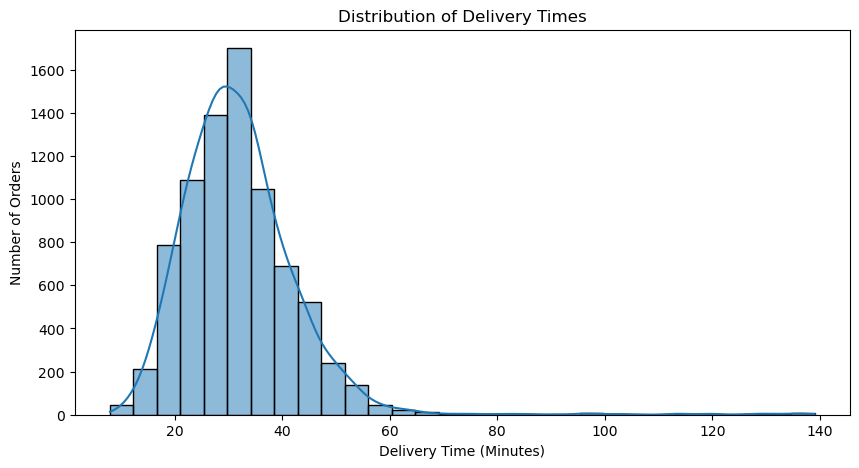

In [11]:
plt.figure(figsize=(10, 5))

sns.histplot(
    train["delivery_minutes"],
    bins=30,
    kde=True
)

plt.title("Distribution of Delivery Times")
plt.xlabel("Delivery Time (Minutes)")
plt.ylabel("Number of Orders")

plt.show()

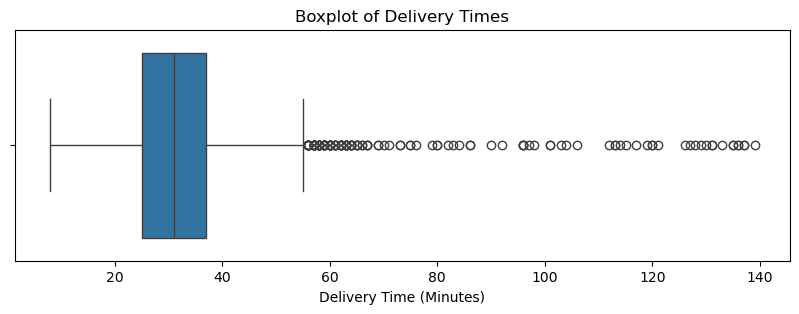

In [15]:
plt.figure(figsize=(10, 3))

sns.boxplot(x=train["delivery_minutes"])

plt.title("Boxplot of Delivery Times")
plt.xlabel("Delivery Time (Minutes)")

plt.show()

In [17]:
# Calculate the first and third quartiles

Q1 = train["delivery_minutes"].quantile(0.25)
Q3 = train["delivery_minutes"].quantile(0.75)

# Calculate IQR

IQR = Q3 - Q1

# Calculate outlier boundaries

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

# Identify potential outliers

outliers = train[
    (train["delivery_minutes"] < lower_bound) |
    (train["delivery_minutes"] > upper_bound)
]

# Calculate the number and percentage

outlier_count = len(outliers)
outlier_percentage = (outlier_count / len(train)) * 100

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("\nPotential Outlier Count:", outlier_count)
print("Potential Outlier Percentage:", round(outlier_percentage, 2), "%")

print("\nMinimum Delivery Time:", train["delivery_minutes"].min())
print("Maximum Delivery Time:", train["delivery_minutes"].max())

Lower Bound: 7.0
Upper Bound: 55.0

Potential Outlier Count: 146
Potential Outlier Percentage: 1.82 %

Minimum Delivery Time: 8
Maximum Delivery Time: 139


In [19]:
# Select numerical features for correlation analysis

numeric_features = [
    "restaurant_avg_prep_minutes",
    "distance_km",
    "items_count",
    "order_subtotal",
    "courier_trips_completed",
    "delivery_minutes"
]

# Calculate correlation matrix

correlation_matrix = train[numeric_features].corr()

# Display correlation with delivery time

delivery_correlation = correlation_matrix["delivery_minutes"].drop(
    "delivery_minutes"
).sort_values(ascending=False)

print("CORRELATION WITH DELIVERY TIME:")
display(delivery_correlation)

CORRELATION WITH DELIVERY TIME:


distance_km                    0.530952
restaurant_avg_prep_minutes    0.405956
items_count                    0.123527
order_subtotal                 0.109180
courier_trips_completed       -0.036856
Name: delivery_minutes, dtype: float64

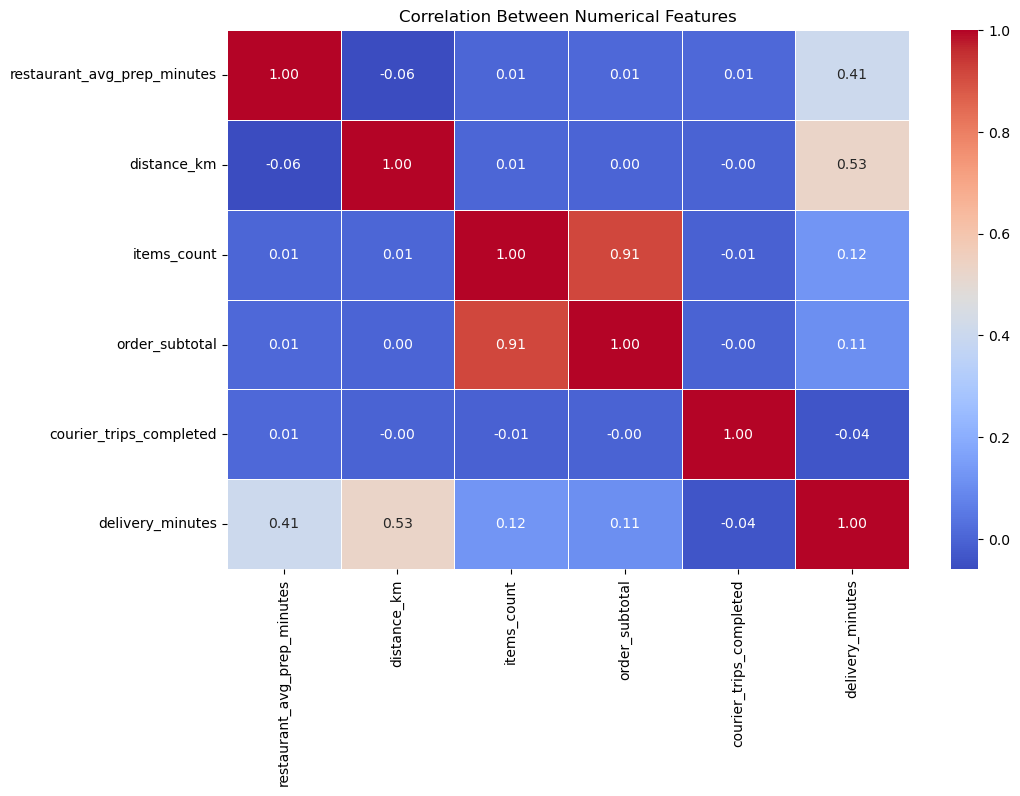

In [21]:
plt.figure(figsize=(11, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Numerical Features")

plt.show()

In [23]:
# Analyse categorical features

categorical_features = [
    "cuisine",
    "city_zone",
    "weather",
    "courier_vehicle"
]

for column in categorical_features:

    print("\nDELIVERY TIME ANALYSIS BY:", column.upper())

    summary = (
        train.groupby(column, dropna=False)["delivery_minutes"]
        .agg(["count", "mean", "median", "std"])
        .round(2)
        .sort_values("mean", ascending=False)
    )

    display(summary)


DELIVERY TIME ANALYSIS BY: CUISINE


,count,mean,median,std
cuisine,,,,
indian,1209,37.83,36.0,11.84
sushi,775,35.33,34.0,9.48
pizza,1330,32.76,32.0,10.08
thai,1500,32.75,32.0,10.46
chinese,801,31.96,31.0,10.76
burgers,488,28.95,27.0,11.26
mexican,951,28.59,27.0,10.67
salads,946,25.02,24.0,9.21



DELIVERY TIME ANALYSIS BY: CITY_ZONE


,count,mean,median,std
city_zone,,,,
suburbs_north,786,40.45,39.0,11.71
suburbs_south,1068,38.33,38.0,10.64
uptown,1530,31.12,31.0,9.89
midtown,2185,30.86,30.0,10.76
downtown,2431,28.23,28.0,9.63



DELIVERY TIME ANALYSIS BY: WEATHER


,count,mean,median,std
weather,,,,
heavy_rain,411,36.89,35.0,13.27
rain,1011,34.24,33.0,11.74
NaN,228,31.78,30.5,11.13
clear,4522,31.42,30.0,11.08
cloudy,1828,31.33,31.0,9.96



DELIVERY TIME ANALYSIS BY: COURIER_VEHICLE


,count,mean,median,std
courier_vehicle,,,,
bike,2567,32.78,32.0,10.27
car,2284,32.72,31.0,12.39
scooter,3149,30.97,30.0,10.79


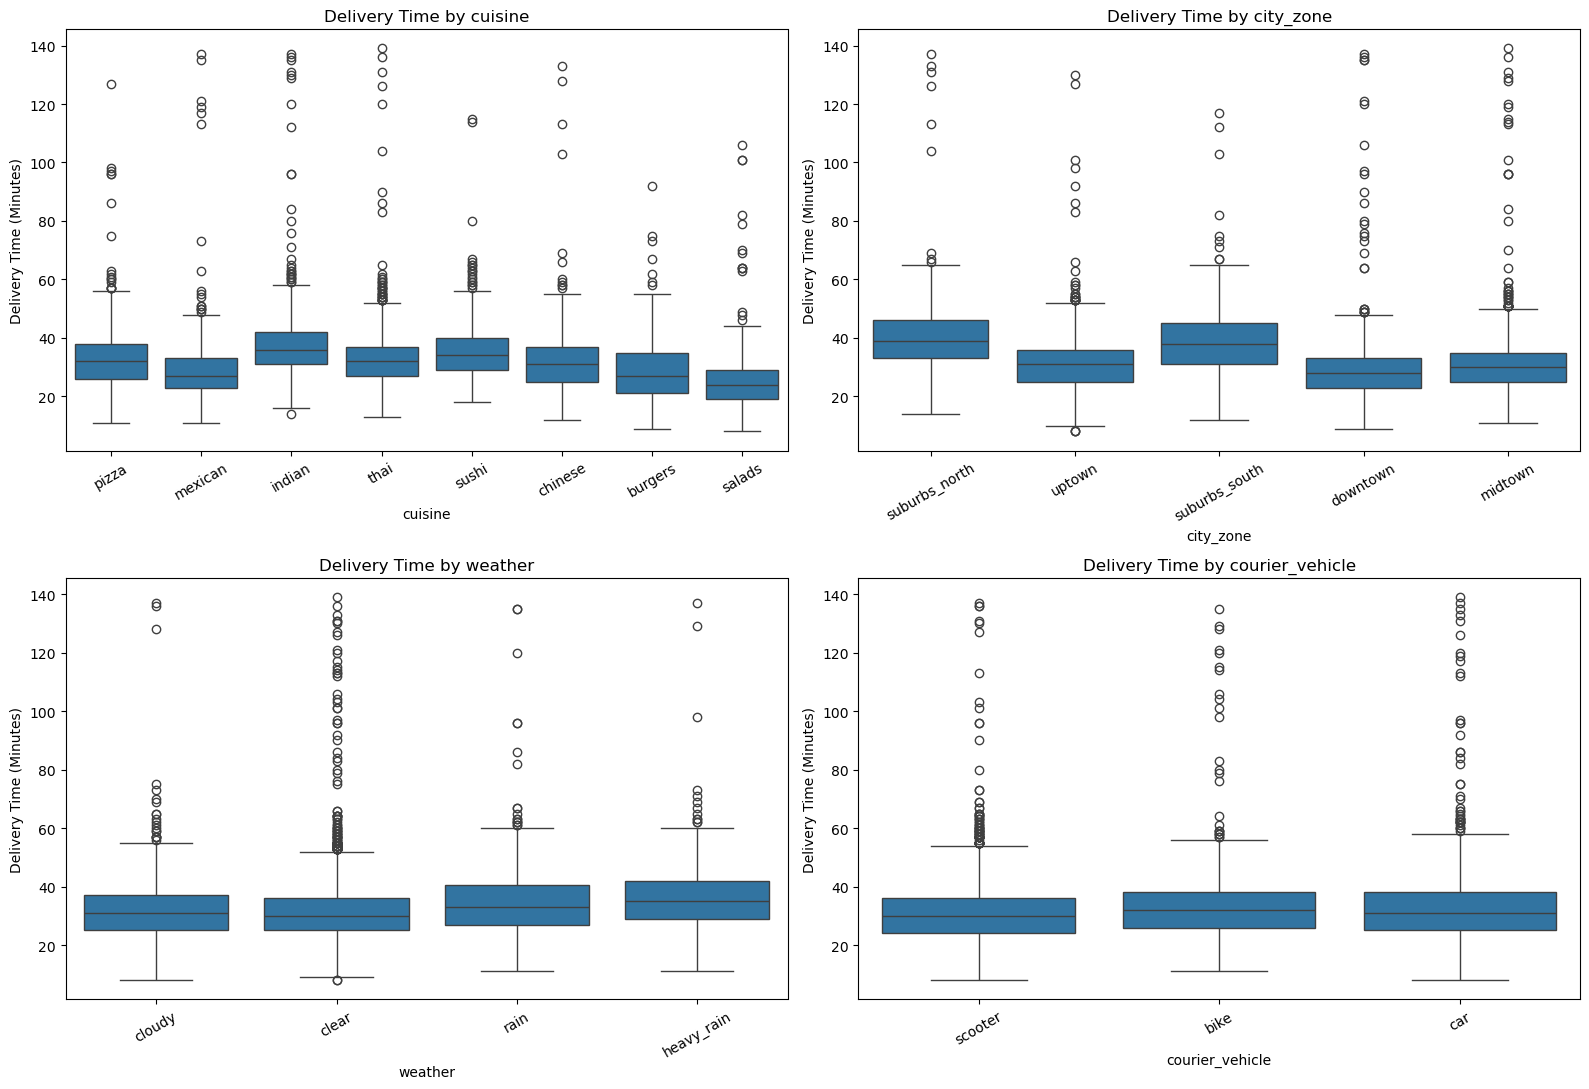

In [25]:
# Compare delivery times across categorical features

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

for column, ax in zip(categorical_features, axes.flatten()):

    sns.boxplot(
        data=train,
        x=column,
        y="delivery_minutes",
        ax=ax
    )

    ax.set_title(f"Delivery Time by {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Delivery Time (Minutes)")

    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [27]:
# Convert order_placed_at into datetime format

order_times = pd.to_datetime(
    train["order_placed_at"],
    errors="coerce"
)

# Check whether conversion was successful

print("Total orders:", len(order_times))

print(
    "Invalid timestamps:",
    order_times.isna().sum()
)

print("\nEarliest order:", order_times.min())
print("Latest order:", order_times.max())

Total orders: 8000
Invalid timestamps: 0

Earliest order: 2025-03-01 10:00:00
Latest order: 2025-08-31 23:42:00


In [29]:
# Create a temporary analysis dataframe

time_analysis = pd.DataFrame({
    "hour": order_times.dt.hour,
    "delivery_minutes": train["delivery_minutes"]
})

# Calculate delivery time by hour

hourly_summary = (
    time_analysis
    .groupby("hour")["delivery_minutes"]
    .agg(["count", "mean", "median"])
    .round(2)
)

print("DELIVERY TIME BY HOUR")

display(hourly_summary)

DELIVERY TIME BY HOUR


,count,mean,median
hour,,,
10,246,28.43,27.0
11,626,33.41,32.0
12,938,32.92,32.0
13,780,33.78,32.0
14,330,29.56,29.0
15,245,29.69,29.0
16,336,29.45,28.0
17,670,30.09,29.0
18,1026,33.82,32.0


In [31]:
# Extract day of the week

time_analysis["day_of_week"] = order_times.dt.dayofweek

# Calculate delivery time by day

weekday_summary = (
    time_analysis
    .groupby("day_of_week")["delivery_minutes"]
    .agg(["count", "mean", "median"])
    .round(2)
)

# Convert numerical days into names

weekday_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}

weekday_summary.index = weekday_summary.index.map(weekday_names)

print("DELIVERY TIME BY DAY OF WEEK")

display(weekday_summary)

DELIVERY TIME BY DAY OF WEEK


,count,mean,median
day_of_week,,,
Monday,1168,31.75,30.0
Tuesday,1171,32.04,31.0
Wednesday,1143,31.85,31.0
Thursday,1131,31.35,30.0
Friday,1088,31.15,30.0
Saturday,1129,33.29,32.0
Sunday,1170,32.86,32.0


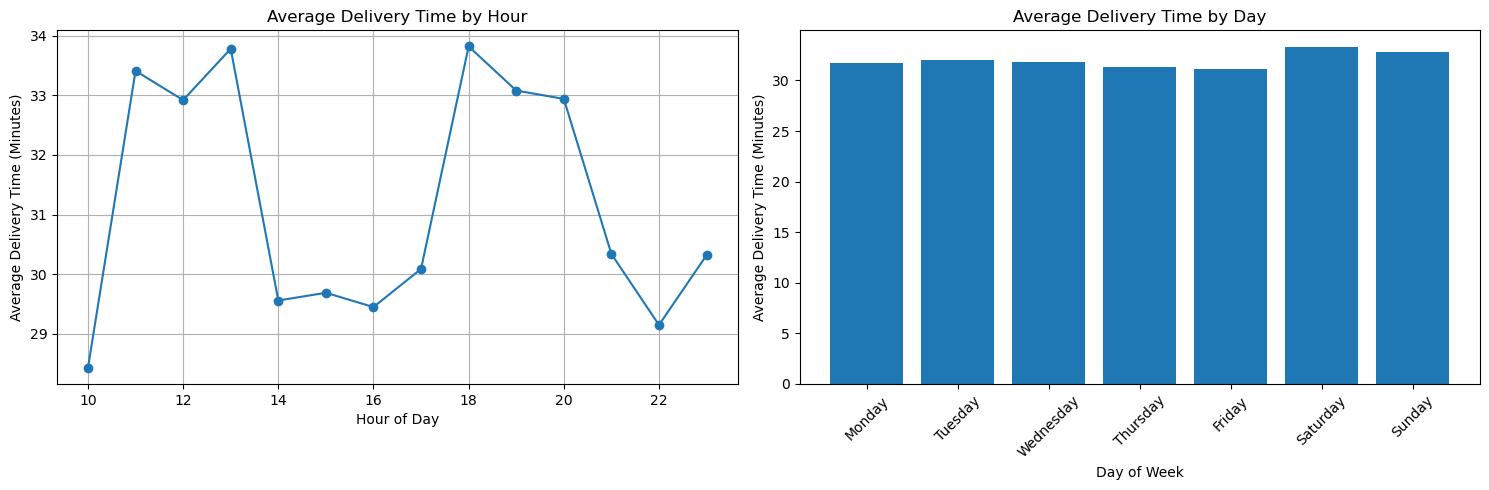

In [33]:
# Create two visualisations

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Average delivery time by hour

axes[0].plot(
    hourly_summary.index,
    hourly_summary["mean"],
    marker="o"
)

axes[0].set_title("Average Delivery Time by Hour")
axes[0].set_xlabel("Hour of Day")
axes[0].set_ylabel("Average Delivery Time (Minutes)")
axes[0].grid(True)

# Average delivery time by weekday

axes[1].bar(
    weekday_summary.index,
    weekday_summary["mean"]
)

axes[1].set_title("Average Delivery Time by Day")
axes[1].set_xlabel("Day of Week")
axes[1].set_ylabel("Average Delivery Time (Minutes)")

axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [35]:
# Compare training and testing columns

train_features = set(train.columns) - {"delivery_minutes"}
test_features = set(test.columns)

print("MISSING COLUMNS IN TEST:")
print(sorted(train_features - test_features))

print("\nUNEXPECTED COLUMNS IN TEST:")
print(sorted(test_features - train_features))

# Check order ID uniqueness

print("\nORDER ID CHECKS")

print("Training IDs unique:", train["order_id"].is_unique)
print("Testing IDs unique:", test["order_id"].is_unique)

# Check whether IDs overlap

overlap = train["order_id"].isin(test["order_id"]).sum()

print("Overlapping order IDs:", overlap)

MISSING COLUMNS IN TEST:
[]

UNEXPECTED COLUMNS IN TEST:
[]

ORDER ID CHECKS
Training IDs unique: True
Testing IDs unique: True
Overlapping order IDs: 0


In [37]:
# Check category counts

for column in ["cuisine", "city_zone", "weather", "courier_vehicle"]:

    print("\nCATEGORY DISTRIBUTION:", column.upper())

    display(
        train[column]
        .value_counts(dropna=False)
    )

# Check restaurant variety

print(
    "\nUnique restaurants:",
    train["restaurant_id"].nunique()
)


CATEGORY DISTRIBUTION: CUISINE


cuisine
thai       1500
pizza      1330
indian     1209
mexican     951
salads      946
chinese     801
sushi       775
burgers     488
Name: count, dtype: int64


CATEGORY DISTRIBUTION: CITY_ZONE


city_zone
downtown         2431
midtown          2185
uptown           1530
suburbs_south    1068
suburbs_north     786
Name: count, dtype: int64


CATEGORY DISTRIBUTION: WEATHER


weather
clear         4522
cloudy        1828
rain          1011
heavy_rain     411
NaN            228
Name: count, dtype: int64


CATEGORY DISTRIBUTION: COURIER_VEHICLE


courier_vehicle
scooter    3149
bike       2567
car        2284
Name: count, dtype: int64


Unique restaurants: 160


In [39]:
# Create separate working copies

train_clean = train.copy()
test_clean = test.copy()

print("Working copies created successfully!")

print("\nOriginal Training Shape:", train.shape)
print("Clean Training Shape:", train_clean.shape)

print("\nOriginal Testing Shape:", test.shape)
print("Clean Testing Shape:", test_clean.shape)

Working copies created successfully!

Original Training Shape: (8000, 13)
Clean Training Shape: (8000, 13)

Original Testing Shape: (2000, 12)
Clean Testing Shape: (2000, 12)


## Calculate missing values in training data

train_missing = pd.DataFrame({
    "Missing Count": train_clean.isnull().sum(),
    "Missing Percentage": (
        train_clean.isnull().mean() * 100
    ).round(2)
})

print("TRAINING DATA MISSING VALUE SUMMARY")
display(train_missing[train_missing["Missing Count"] > 0])


# Calculate missing values in testing data

test_missing = pd.DataFrame({
    "Missing Count": test_clean.isnull().sum(),
    "Missing Percentage": (
        test_clean.isnull().mean() * 100
    ).round(2)
})

print("TESTING DATA MISSING VALUE SUMMARY")
display(test_missing[test_missing["Missing Count"] > 0])

In [42]:
# Calculate missing values in training data

train_missing = pd.DataFrame({
    "Missing Count": train_clean.isnull().sum(),
    "Missing Percentage": (
        train_clean.isnull().mean() * 100
    ).round(2)
})

print("TRAINING DATA MISSING VALUE SUMMARY")
display(train_missing[train_missing["Missing Count"] > 0])


# Calculate missing values in testing data

test_missing = pd.DataFrame({
    "Missing Count": test_clean.isnull().sum(),
    "Missing Percentage": (
        test_clean.isnull().mean() * 100
    ).round(2)
})

print("TESTING DATA MISSING VALUE SUMMARY")
display(test_missing[test_missing["Missing Count"] > 0])

TRAINING DATA MISSING VALUE SUMMARY


,Missing Count,Missing Percentage
courier_trips_completed,329,4.11
weather,228,2.85


TESTING DATA MISSING VALUE SUMMARY


,Missing Count,Missing Percentage
courier_trips_completed,75,3.75
weather,51,2.55


In [44]:
# Replace missing weather values with Unknown

train_clean["weather"] = train_clean["weather"].fillna("Unknown")

test_clean["weather"] = test_clean["weather"].fillna("Unknown")


# Verify missing values

print("Missing weather values after cleaning:")

print(
    "Training:",
    train_clean["weather"].isnull().sum()
)

print(
    "Testing:",
    test_clean["weather"].isnull().sum()
)

Missing weather values after cleaning:
Training: 0
Testing: 0


In [46]:
# Check invalid delivery times

print("Target variable validation")

print(
    "Missing delivery times:",
    train_clean["delivery_minutes"].isnull().sum()
)

print(
    "Zero or negative delivery times:",
    (train_clean["delivery_minutes"] <= 0).sum()
)

# Count potential upper outliers

upper_outliers = train_clean[
    train_clean["delivery_minutes"] > 55
]

print(
    "\nPotential upper outliers:",
    len(upper_outliers)
)

print(
    "Percentage:",
    round(len(upper_outliers) / len(train_clean) * 100, 2),
    "%"
)

# Examine aggregate statistics of potential outliers

print("\nOutlier delivery-time statistics:")

print(
    upper_outliers["delivery_minutes"].describe()
)

Target variable validation
Missing delivery times: 0
Zero or negative delivery times: 0

Potential upper outliers: 146
Percentage: 1.82 %

Outlier delivery-time statistics:
count    146.000000
mean      76.582192
std       25.841361
min       56.000000
25%       58.000000
50%       63.000000
75%       91.500000
max      139.000000
Name: delivery_minutes, dtype: float64


In [48]:
# Convert order_placed_at in both working datasets

train_clean["order_placed_at"] = pd.to_datetime(
    train_clean["order_placed_at"],
    errors="coerce"
)

test_clean["order_placed_at"] = pd.to_datetime(
    test_clean["order_placed_at"],
    errors="coerce"
)


# Verify data types

print("TRAINING DATETIME TYPE:")
print(train_clean["order_placed_at"].dtype)

print("\nTESTING DATETIME TYPE:")
print(test_clean["order_placed_at"].dtype)


# Check invalid timestamps

print("\nINVALID TIMESTAMPS")

print(
    "Training:",
    train_clean["order_placed_at"].isnull().sum()
)

print(
    "Testing:",
    test_clean["order_placed_at"].isnull().sum()
)

TRAINING DATETIME TYPE:
datetime64[ns]

TESTING DATETIME TYPE:
datetime64[ns]

INVALID TIMESTAMPS
Training: 0
Testing: 0


In [50]:
# Check categorical consistency

categorical_columns = [
    "cuisine",
    "city_zone",
    "weather",
    "courier_vehicle"
]

for column in categorical_columns:

    print("\nChecking:", column)

    train_values = set(
        train_clean[column].dropna().astype(str)
    )

    test_values = set(
        test_clean[column].dropna().astype(str)
    )

    # Check categories present in test but absent in train
    unseen_categories = test_values - train_values

    # Check leading or trailing spaces
    train_spaces = (
        train_clean[column]
        .dropna()
        .astype(str)
        .ne(
            train_clean[column]
            .dropna()
            .astype(str)
            .str.strip()
        )
        .sum()
    )

    test_spaces = (
        test_clean[column]
        .dropna()
        .astype(str)
        .ne(
            test_clean[column]
            .dropna()
            .astype(str)
            .str.strip()
        )
        .sum()
    )

    print("Unseen test categories:", sorted(unseen_categories))
    print("Training values with extra spaces:", train_spaces)
    print("Testing values with extra spaces:", test_spaces)


Checking: cuisine
Unseen test categories: []
Training values with extra spaces: 0
Testing values with extra spaces: 0

Checking: city_zone
Unseen test categories: []
Training values with extra spaces: 0
Testing values with extra spaces: 0

Checking: weather
Unseen test categories: []
Training values with extra spaces: 0
Testing values with extra spaces: 0

Checking: courier_vehicle
Unseen test categories: []
Training values with extra spaces: 0
Testing values with extra spaces: 0


In [52]:
# Numerical data validation

numeric_columns = [
    "restaurant_avg_prep_minutes",
    "distance_km",
    "items_count",
    "order_subtotal",
    "courier_trips_completed",
    "delivery_minutes"
]

for dataset_name, dataset in [
    ("TRAINING", train_clean),
    ("TESTING", test_clean)
]:

    print("\n", "=" * 45)
    print(dataset_name, "NUMERICAL VALIDATION")
    print("=" * 45)

    for column in numeric_columns:

        if column not in dataset.columns:
            continue

        values = dataset[column]

        print("\nColumn:", column)
        print("Missing:", values.isna().sum())
        print("Minimum:", values.min())
        print("Maximum:", values.max())

        # Check infinite values
        print(
            "Infinite values:",
            np.isinf(values.dropna()).sum()
        )

        # Check negative values
        print(
            "Negative values:",
            (values < 0).sum()
        )


TRAINING NUMERICAL VALIDATION

Column: restaurant_avg_prep_minutes
Missing: 0
Minimum: 5.0
Maximum: 22.3
Infinite values: 0
Negative values: 0

Column: distance_km
Missing: 0
Minimum: 0.6
Maximum: 13.3
Infinite values: 0
Negative values: 0

Column: items_count
Missing: 0
Minimum: 1
Maximum: 8
Infinite values: 0
Negative values: 0

Column: order_subtotal
Missing: 0
Minimum: 8.0
Maximum: 127.64
Infinite values: 0
Negative values: 0

Column: courier_trips_completed
Missing: 329
Minimum: 1.0
Maximum: 45151.0
Infinite values: 0
Negative values: 0

Column: delivery_minutes
Missing: 0
Minimum: 8
Maximum: 139
Infinite values: 0
Negative values: 0

TESTING NUMERICAL VALIDATION

Column: restaurant_avg_prep_minutes
Missing: 0
Minimum: 5.0
Maximum: 22.3
Infinite values: 0
Negative values: 0

Column: distance_km
Missing: 0
Minimum: 0.6
Maximum: 13.1
Infinite values: 0
Negative values: 0

Column: items_count
Missing: 0
Minimum: 1
Maximum: 8
Infinite values: 0
Negative values: 0

Column: order_subto

In [54]:
# Final numerical quality check

for name, dataset in [
    ("TRAINING", train_clean),
    ("TESTING", test_clean)
]:

    columns = [
        col for col in numeric_columns
        if col in dataset.columns
    ]

    numeric_data = dataset[columns]

    print("\n", name, "DATASET")

    print("\nNegative value counts:")
    display(numeric_data.lt(0).sum())

    print("\nInfinite value counts:")
    print(
        pd.Series(
            np.isinf(numeric_data).sum(),
            index=columns
        )
    )


 TRAINING DATASET

Negative value counts:


restaurant_avg_prep_minutes    0
distance_km                    0
items_count                    0
order_subtotal                 0
courier_trips_completed        0
delivery_minutes               0
dtype: int64


Infinite value counts:
restaurant_avg_prep_minutes    0
distance_km                    0
items_count                    0
order_subtotal                 0
courier_trips_completed        0
delivery_minutes               0
dtype: int64

 TESTING DATASET

Negative value counts:


restaurant_avg_prep_minutes    0
distance_km                    0
items_count                    0
order_subtotal                 0
courier_trips_completed        0
dtype: int64


Infinite value counts:
restaurant_avg_prep_minutes    0
distance_km                    0
items_count                    0
order_subtotal                 0
courier_trips_completed        0
dtype: int64


In [56]:
# Check restaurant IDs across training and testing

train_restaurants = set(train_clean["restaurant_id"].unique())

test_restaurants = set(test_clean["restaurant_id"].unique())

unseen_restaurants = test_restaurants - train_restaurants

print("Restaurant ID analysis")

print("Unique training restaurants:", len(train_restaurants))

print("Unique testing restaurants:", len(test_restaurants))

print("Unseen restaurants in testing:", len(unseen_restaurants))

# Final weather verification

print("\nWeather missing values:")

print("Training:", train_clean["weather"].isnull().sum())

print("Testing:", test_clean["weather"].isnull().sum())

# Final timestamp verification

print("\nInvalid timestamps:")

print("Training:", train_clean["order_placed_at"].isnull().sum())

print("Testing:", test_clean["order_placed_at"].isnull().sum())

Restaurant ID analysis
Unique training restaurants: 160
Unique testing restaurants: 160
Unseen restaurants in testing: 0

Weather missing values:
Training: 0
Testing: 0

Invalid timestamps:
Training: 0
Testing: 0


In [58]:
# Feature Engineering: Time-based features

# Create features for training and testing datasets

for dataset in [train_clean, test_clean]:

    # Extract hour of the order
    dataset["order_hour"] = (
        dataset["order_placed_at"].dt.hour
    )

    # Extract day of the week
    dataset["day_of_week"] = (
        dataset["order_placed_at"].dt.day_name()
    )

    # Extract month
    dataset["order_month"] = (
        dataset["order_placed_at"].dt.month
    )

    # Identify weekend orders
    dataset["is_weekend"] = (
        dataset["order_placed_at"]
        .dt.dayofweek
        .isin([5, 6])
        .astype(int)
    )

    # Classify the time period
    hour = dataset["order_hour"]

    conditions = [
        hour < 12,
        (hour >= 12) & (hour < 17),
        (hour >= 17) & (hour < 21),
        hour >= 21
    ]

    choices = [
        "Morning",
        "Afternoon",
        "Evening",
        "Late_Evening"
    ]

    dataset["time_period"] = np.select(
        conditions,
        choices,
        default="Unknown"
    )

print("Time-based features created successfully!")

Time-based features created successfully!


In [60]:
# Verify new features

new_features = [
    "order_hour",
    "day_of_week",
    "order_month",
    "is_weekend",
    "time_period"
]

print("TRAINING DATASET")
print("New features:", new_features)
print("\nMissing values:")
display(train_clean[new_features].isnull().sum())

print("\nTesting dataset missing values:")
display(test_clean[new_features].isnull().sum())

print("\nTime period distribution in training:")
display(train_clean["time_period"].value_counts())

print("\nWeekend distribution in training:")
display(train_clean["is_weekend"].value_counts())

TRAINING DATASET
New features: ['order_hour', 'day_of_week', 'order_month', 'is_weekend', 'time_period']

Missing values:


order_hour     0
day_of_week    0
order_month    0
is_weekend     0
time_period    0
dtype: int64


Testing dataset missing values:


order_hour     0
day_of_week    0
order_month    0
is_weekend     0
time_period    0
dtype: int64


Time period distribution in training:


time_period
Evening         3506
Afternoon       2629
Late_Evening     993
Morning          872
Name: count, dtype: int64


Weekend distribution in training:


is_weekend
0    5701
1    2299
Name: count, dtype: int64

In [62]:
# Create peak-order feature

peak_hours = [11, 12, 13, 18, 19, 20]

for dataset in [train_clean, test_clean]:

    dataset["is_peak_order"] = (
        dataset["order_hour"]
        .isin(peak_hours)
        .astype(int)
    )

print("Peak-order feature created successfully!")

Peak-order feature created successfully!


In [64]:
# Check peak and non-peak order distribution

print("PEAK ORDER DISTRIBUTION")

display(
    train_clean["is_peak_order"].value_counts()
)

# Compare delivery times

print("\nDELIVERY TIME COMPARISON")

display(
    train_clean.groupby("is_peak_order")["delivery_minutes"]
    .agg(["count", "mean", "median"])
    .round(2)
)

PEAK ORDER DISTRIBUTION


is_peak_order
1    5180
0    2820
Name: count, dtype: int64


DELIVERY TIME COMPARISON


,count,mean,median
is_peak_order,,,
0,2820,29.71,29.0
1,5180,33.32,32.0


In [66]:
# Remove target-informed peak feature

train_clean.drop(
    columns=["is_peak_order"],
    inplace=True,
    errors="ignore"
)

test_clean.drop(
    columns=["is_peak_order"],
    inplace=True,
    errors="ignore"
)


# Create distance and preparation interaction

for dataset in [train_clean, test_clean]:

    dataset["distance_prep_interaction"] = (
        dataset["distance_km"] *
        dataset["restaurant_avg_prep_minutes"]
    )


print("Feature interaction created successfully!")

Feature interaction created successfully!


In [68]:
# Verify interaction feature

print("TRAINING FEATURE CHECK")

print(
    train_clean[
        ["distance_km",
         "restaurant_avg_prep_minutes",
         "distance_prep_interaction"]
    ].isnull().sum()
)

print("\nInteraction feature statistics:")

print(
    train_clean["distance_prep_interaction"].describe()
)

print("\nTesting missing values:")

print(
    test_clean["distance_prep_interaction"].isnull().sum()
)

TRAINING FEATURE CHECK
distance_km                    0
restaurant_avg_prep_minutes    0
distance_prep_interaction      0
dtype: int64

Interaction feature statistics:
count    8000.000000
mean       49.025224
std        35.206898
min         4.550000
25%        24.800000
50%        39.270000
75%        62.115000
max       267.600000
Name: distance_prep_interaction, dtype: float64

Testing missing values:
0


In [70]:
# FINAL FEATURE SELECTION

# Numerical features
numeric_features = [
    "restaurant_avg_prep_minutes",
    "distance_km",
    "items_count",
    "order_subtotal",
    "order_hour",
    "order_month",
    "is_weekend",
    "distance_prep_interaction"
]


# Categorical features
categorical_features = [
    "restaurant_id",
    "cuisine",
    "city_zone",
    "weather",
    "day_of_week",
    "time_period"
]


# Combine all features
model_features = numeric_features + categorical_features


# Features excluded from modelling
excluded_features = [
    "order_id",
    "order_placed_at",
    "courier_vehicle",
    "courier_trips_completed",
    "delivery_minutes"
]


# Display final feature selection

print("NUMERICAL FEATURES:")
print(numeric_features)

print("\nCATEGORICAL FEATURES:")
print(categorical_features)

print("\nTOTAL MODEL FEATURES:", len(model_features))

print("\nEXCLUDED FEATURES:")
print(excluded_features)

NUMERICAL FEATURES:
['restaurant_avg_prep_minutes', 'distance_km', 'items_count', 'order_subtotal', 'order_hour', 'order_month', 'is_weekend', 'distance_prep_interaction']

CATEGORICAL FEATURES:
['restaurant_id', 'cuisine', 'city_zone', 'weather', 'day_of_week', 'time_period']

TOTAL MODEL FEATURES: 14

EXCLUDED FEATURES:
['order_id', 'order_placed_at', 'courier_vehicle', 'courier_trips_completed', 'delivery_minutes']


In [72]:
# Verify selected features exist in both datasets

print("TRAINING FEATURE CHECK:")
print(set(model_features).issubset(train_clean.columns))

print("\nTESTING FEATURE CHECK:")
print(set(model_features).issubset(test_clean.columns))


# Check missing values in selected features

print("\nMISSING VALUES IN TRAINING FEATURES:")
print(train_clean[model_features].isnull().sum().sum())

print("\nMISSING VALUES IN TESTING FEATURES:")
print(test_clean[model_features].isnull().sum().sum())


# Check for target leakage

print("\nTARGET INCLUDED IN MODEL FEATURES:")
print("delivery_minutes" in model_features)

print("\nPEAK FEATURE INCLUDED:")
print("is_peak_order" in model_features)

TRAINING FEATURE CHECK:
True

TESTING FEATURE CHECK:
True

MISSING VALUES IN TRAINING FEATURES:
0

MISSING VALUES IN TESTING FEATURES:
0

TARGET INCLUDED IN MODEL FEATURES:
False

PEAK FEATURE INCLUDED:
False


In [74]:
# Sort training data chronologically

ordered_train = train_clean.sort_values(
    "order_placed_at"
).copy()

# Find unique calendar dates

unique_dates = pd.Index(
    ordered_train["order_placed_at"].dt.normalize().unique()
).sort_values()

# Select the date that starts the final 20%

split_position = int(len(unique_dates) * 0.80)
split_date = unique_dates[split_position]

# Split by calendar date

train_part = ordered_train[
    ordered_train["order_placed_at"].dt.normalize() < split_date
].copy()

valid_part = ordered_train[
    ordered_train["order_placed_at"].dt.normalize() >= split_date
].copy()

# Separate input features and target variable

X_train = train_part[model_features].copy()
y_train = train_part["delivery_minutes"].copy()

X_valid = valid_part[model_features].copy()
y_valid = valid_part["delivery_minutes"].copy()

# Display results

print("TRAINING AND VALIDATION SPLIT")
print("--------------------------------")

print("Training records:", len(X_train))
print("Validation records:", len(X_valid))

print("\nTraining features shape:", X_train.shape)
print("Validation features shape:", X_valid.shape)

print("\nTraining date range:")
print(train_part["order_placed_at"].min())
print("to", train_part["order_placed_at"].max())

print("\nValidation date range:")
print(valid_part["order_placed_at"].min())
print("to", valid_part["order_placed_at"].max())

print("\nChronological split verified:",
      train_part["order_placed_at"].max()
      < valid_part["order_placed_at"].min())

TRAINING AND VALIDATION SPLIT
--------------------------------
Training records: 6368
Validation records: 1632

Training features shape: (6368, 14)
Validation features shape: (1632, 14)

Training date range:
2025-03-01 10:00:00
to 2025-07-25 22:55:00

Validation date range:
2025-07-26 10:28:00
to 2025-08-31 23:42:00

Chronological split verified: True


In [76]:
# Import evaluation metric

from sklearn.metrics import mean_absolute_error

# Calculate average delivery time from training data only

baseline_mean = y_train.mean()

# Predict the same average for every validation order

baseline_predictions = np.full(
    len(y_valid),
    baseline_mean
)

# Evaluate using MAE

baseline_mean_mae = mean_absolute_error(
    y_valid,
    baseline_predictions
)

# Display results

print("AVERAGE BASELINE MODEL")
print("----------------------")

print("Average training delivery time:",
      round(baseline_mean, 2), "minutes")

print("Validation MAE:",
      round(baseline_mean_mae, 2), "minutes")

AVERAGE BASELINE MODEL
----------------------
Average training delivery time: 32.02 minutes
Validation MAE: 7.63 minutes


In [78]:
# Calculate median delivery time using training data

baseline_median = y_train.median()

# Predict the median for every validation order

median_predictions = np.full(
    len(y_valid),
    baseline_median
)

# Evaluate median baseline

baseline_median_mae = mean_absolute_error(
    y_valid,
    median_predictions
)

print("BASELINE COMPARISON")
print("-------------------")

print("Mean baseline MAE:",
      round(baseline_mean_mae, 2), "minutes")

print("Median baseline MAE:",
      round(baseline_median_mae, 2), "minutes")

BASELINE COMPARISON
-------------------
Mean baseline MAE: 7.63 minutes
Median baseline MAE: 7.58 minutes


In [80]:
# Create a reusable model evaluation function

from sklearn.metrics import mean_absolute_error

def evaluate_model(model_name, actual, predicted):

    mae = mean_absolute_error(actual, predicted)

    return {
        "Model": model_name,
        "MAE (Minutes)": round(mae, 4)
    }


# Store baseline results

model_results = []

model_results.append(
    evaluate_model(
        "Mean Baseline",
        y_valid,
        baseline_predictions
    )
)

model_results.append(
    evaluate_model(
        "Median Baseline",
        y_valid,
        median_predictions
    )
)


# Display comparison

baseline_results = pd.DataFrame(model_results)

display(
    baseline_results.sort_values(
        "MAE (Minutes)"
    )
)

# Store the best baseline score

best_baseline_mae = min(
    result["MAE (Minutes)"]
    for result in model_results
)

print(
    "\nBest baseline MAE:",
    best_baseline_mae,
    "minutes"
)

,Model,MAE (Minutes)
1,Median Baseline,7.5809
0,Mean Baseline,7.6338



Best baseline MAE: 7.5809 minutes


In [82]:
# Import required libraries

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression


# Step 1: Prepare preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),

        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)


# Step 2: Create Linear Regression model

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)


# Step 3: Train the model

linear_model.fit(X_train, y_train)


# Step 4: Generate validation predictions

linear_predictions = linear_model.predict(X_valid)


# Step 5: Evaluate the model

linear_mae = mean_absolute_error(
    y_valid,
    linear_predictions
)


# Step 6: Store results

linear_result = evaluate_model(
    "Linear Regression",
    y_valid,
    linear_predictions
)

model_results.append(linear_result)


# Display results

print("LINEAR REGRESSION RESULTS")
print("-------------------------")

print("Validation MAE:",
      round(linear_mae, 4), "minutes")

print("\nImprovement compared with best baseline:")

improvement = (
    (best_baseline_mae - linear_mae)
    / best_baseline_mae
) * 100

print(round(improvement, 2), "%")

LINEAR REGRESSION RESULTS
-------------------------
Validation MAE: 3.9573 minutes

Improvement compared with best baseline:
47.8 %


In [84]:
# Import Random Forest Regressor

from sklearn.ensemble import RandomForestRegressor


# Step 1: Prepare preprocessing

# Random Forest does not require numerical scaling

rf_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", numeric_features),

        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)


# Step 2: Create Random Forest model

rf_model = Pipeline(
    steps=[
        ("preprocessor", rf_preprocessor),

        ("model", RandomForestRegressor(
            n_estimators=300,
            min_samples_leaf=2,
            max_features=0.8,
            random_state=42,
            n_jobs=-1
        ))
    ]
)


# Step 3: Train the model

rf_model.fit(X_train, y_train)


# Step 4: Generate validation predictions

rf_predictions = rf_model.predict(X_valid)


# Step 5: Evaluate the model

rf_mae = mean_absolute_error(
    y_valid,
    rf_predictions
)


# Step 6: Store the result

rf_result = evaluate_model(
    "Random Forest",
    y_valid,
    rf_predictions
)

model_results.append(rf_result)


# Step 7: Display results

print("RANDOM FOREST RESULTS")
print("---------------------")

print("Validation MAE:",
      round(rf_mae, 4), "minutes")


# Compare with baseline

improvement = (
    (best_baseline_mae - rf_mae)
    / best_baseline_mae
) * 100

print("\nImprovement compared with best baseline:")
print(round(improvement, 2), "%")

RANDOM FOREST RESULTS
---------------------
Validation MAE: 4.0926 minutes

Improvement compared with best baseline:
46.01 %


In [86]:
# Compare all trained models and baselines

results_df = pd.DataFrame(model_results)

results_df = results_df.sort_values(
    "MAE (Minutes)"
).reset_index(drop=True)

print("MODEL PERFORMANCE COMPARISON")

display(results_df)

MODEL PERFORMANCE COMPARISON


,Model,MAE (Minutes)
0,Linear Regression,3.9573
1,Random Forest,4.0926
2,Median Baseline,7.5809
3,Mean Baseline,7.6338


In [88]:
# Generate predictions on training data

linear_train_predictions = linear_model.predict(X_train)

rf_train_predictions = rf_model.predict(X_train)


# Calculate training MAE

linear_train_mae = mean_absolute_error(
    y_train,
    linear_train_predictions
)

rf_train_mae = mean_absolute_error(
    y_train,
    rf_train_predictions
)


# Create evaluation summary

generalization_results = pd.DataFrame({

    "Model": [
        "Linear Regression",
        "Random Forest"
    ],

    "Training MAE": [
        linear_train_mae,
        rf_train_mae
    ],

    "Validation MAE": [
        linear_mae,
        rf_mae
    ]
})

generalization_results["MAE Gap"] = (
    generalization_results["Validation MAE"]
    - generalization_results["Training MAE"]
)

display(
    generalization_results.round(4)
)

,Model,Training MAE,Validation MAE,MAE Gap
0,Linear Regression,4.179,3.9573,-0.2216
1,Random Forest,2.165,4.0926,1.9276


In [90]:
# Compare target distributions

target_comparison = pd.DataFrame({
    "Training": y_train.describe(),
    "Validation": y_valid.describe()
})

print("DELIVERY TIME DISTRIBUTION COMPARISON")

display(target_comparison.round(2))

DELIVERY TIME DISTRIBUTION COMPARISON


,Training,Validation
count,6368.00,1632.00
mean,32.02,32.15
std,11.36,10.26
min,8.00,11.00
25%,25.00,25.00
50%,31.00,31.00
75%,37.00,38.00
max,139.00,136.00


In [92]:
# Compare average delivery times

train_average = y_train.mean()
valid_average = y_valid.mean()

print("Training average:", round(train_average, 2), "minutes")
print("Validation average:", round(valid_average, 2), "minutes")

print(
    "\nDifference:",
    round(valid_average - train_average, 2),
    "minutes"
)

Training average: 32.02 minutes
Validation average: 32.15 minutes

Difference: 0.13 minutes


In [94]:
# Compare detailed validation prediction errors

from sklearn.metrics import median_absolute_error

prediction_comparison = []

models_to_check = [
    ("Linear Regression", linear_predictions),
    ("Random Forest", rf_predictions)
]

for name, predictions in models_to_check:

    absolute_errors = np.abs(
        y_valid.to_numpy() - predictions
    )

    prediction_comparison.append({

        "Model": name,

        "MAE": np.mean(absolute_errors),

        "Median Absolute Error": np.median(absolute_errors),

        "90th Percentile Error": np.percentile(
            absolute_errors, 90
        ),

        "Maximum Error": np.max(absolute_errors),

        "Within 5 Minutes (%)": (
            np.mean(absolute_errors <= 5) * 100
        ),

        "Within 10 Minutes (%)": (
            np.mean(absolute_errors <= 10) * 100
        ),

        "Negative Predictions": (
            np.sum(predictions < 0)
        )
    })


# Display comparison

error_comparison = pd.DataFrame(prediction_comparison)

display(error_comparison.round(2))

,Model,MAE,Median Absolute Error,90th Percentile Error,Maximum Error,Within 5 Minutes (%),Within 10 Minutes (%),Negative Predictions
0,Linear Regression,3.96,3.10,7.63,96.13,72.30,96.38,0
1,Random Forest,4.09,3.07,7.97,95.64,71.88,95.16,0


In [96]:
# Import permutation importance

from sklearn.inspection import permutation_importance

# Calculate permutation importance for Linear Regression

importance_result = permutation_importance(
    linear_model,
    X_valid,
    y_valid,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Create feature importance dataframe

feature_importance = pd.DataFrame({

    "Feature": model_features,

    "Importance": importance_result.importances_mean,

    "Importance_Std": importance_result.importances_std
})

# Sort features by importance

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display results

print("LINEAR REGRESSION - FEATURE IMPORTANCE")

display(feature_importance.round(4))

LINEAR REGRESSION - FEATURE IMPORTANCE


,Feature,Importance,Importance_Std
0,distance_km,4.4752,0.0906
1,restaurant_avg_prep_minutes,2.9530,0.1065
2,items_count,0.3637,0.0313
3,weather,0.2490,0.0203
4,time_period,0.1430,0.0244
5,order_hour,0.0584,0.0140
6,is_weekend,0.0355,0.0218
7,city_zone,0.0138,0.0099
8,cuisine,0.0125,0.0074
9,distance_prep_interaction,0.0091,0.0061


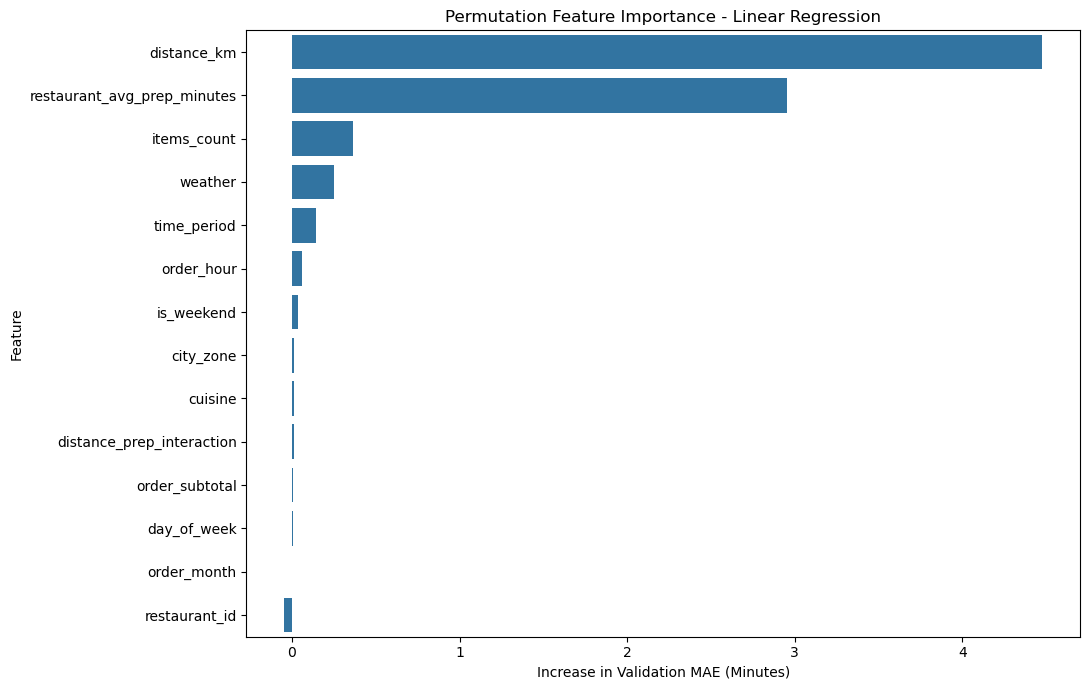

In [98]:
# Visualise feature importance

plt.figure(figsize=(11, 7))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Permutation Feature Importance - Linear Regression")

plt.xlabel("Increase in Validation MAE (Minutes)")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [100]:
# Create validation error analysis dataframe

error_analysis = pd.DataFrame({
    "actual_minutes": y_valid.to_numpy(),
    "predicted_minutes": linear_predictions
})

# Calculate prediction errors

error_analysis["signed_error"] = (
    error_analysis["predicted_minutes"]
    - error_analysis["actual_minutes"]
)

error_analysis["absolute_error"] = (
    error_analysis["signed_error"].abs()
)

print("ERROR ANALYSIS DATASET CREATED!")

print("Total validation orders:", len(error_analysis))

print(
    "Average absolute error:",
    round(error_analysis["absolute_error"].mean(), 4)
)

print(
    "Maximum absolute error:",
    round(error_analysis["absolute_error"].max(), 4)
)

ERROR ANALYSIS DATASET CREATED!
Total validation orders: 1632
Average absolute error: 3.9573
Maximum absolute error: 96.1342


In [102]:
# Group orders by actual delivery time

error_analysis["delivery_category"] = pd.cut(
    error_analysis["actual_minutes"],
    bins=[0, 20, 40, 55, np.inf],
    labels=[
        "Up to 20",
        "21-40",
        "41-55",
        "Above 55"
    ]
)

# Calculate error statistics for each group

error_by_category = (
    error_analysis
    .groupby("delivery_category", observed=False)
    .agg(
        orders=("actual_minutes", "count"),
        average_actual=("actual_minutes", "mean"),
        average_predicted=("predicted_minutes", "mean"),
        MAE=("absolute_error", "mean"),
        median_error=("absolute_error", "median"),
        maximum_error=("absolute_error", "max")
    )
    .round(2)
)

print("PREDICTION ERROR BY DELIVERY CATEGORY")

display(error_by_category)

PREDICTION ERROR BY DELIVERY CATEGORY


,orders,average_actual,average_predicted,MAE,median_error,maximum_error
delivery_category,,,,,,
Up to 20,164,17.65,21.52,4.44,3.75,15.18
21-40,1181,30.31,30.78,3.33,2.83,13.10
41-55,263,45.97,43.22,4.64,3.94,16.30
Above 55,24,70.83,47.12,23.88,7.52,96.13


In [104]:
# Check prediction direction

overpredictions = (
    error_analysis["signed_error"] > 0
).sum()

underpredictions = (
    error_analysis["signed_error"] < 0
).sum()

exact_predictions = (
    error_analysis["signed_error"] == 0
).sum()

print("PREDICTION DIRECTION ANALYSIS")

print("Overpredictions:", overpredictions)
print("Underpredictions:", underpredictions)
print("Exact predictions:", exact_predictions)

print(
    "\nAverage signed error:",
    round(error_analysis["signed_error"].mean(), 2),
    "minutes"
)

PREDICTION DIRECTION ANALYSIS
Overpredictions: 857
Underpredictions: 775
Exact predictions: 0

Average signed error: -0.06 minutes


In [106]:
# Identify the 10 largest prediction errors

worst_predictions = (
    error_analysis
    .nlargest(10, "absolute_error")
    [[
        "actual_minutes",
        "predicted_minutes",
        "signed_error",
        "absolute_error"
    ]]
)

print("TOP 10 LARGEST PREDICTION ERRORS")

display(worst_predictions.round(2))

TOP 10 LARGEST PREDICTION ERRORS


,actual_minutes,predicted_minutes,signed_error,absolute_error
23,136,39.87,-96.13,96.13
43,97,17.76,-79.24,79.24
32,96,32.52,-63.48,63.48
551,98,35.20,-62.80,62.80
480,92,29.95,-62.05,62.05
1276,96,36.41,-59.59,59.59
838,64,16.29,-47.71,47.71
275,51,34.70,-16.30,16.30
1124,49,33.12,-15.88,15.88
1349,55,39.73,-15.27,15.27


In [108]:
# Create diagnostic dataset using validation records

diagnostics = valid_part[
    [
        "distance_km",
        "restaurant_avg_prep_minutes",
        "weather",
        "city_zone",
        "cuisine",
        "time_period",
        "delivery_minutes"
    ]
].reset_index(drop=True).copy()

# Add model predictions

diagnostics["predicted_minutes"] = linear_predictions

# Calculate signed and absolute errors

diagnostics["signed_error"] = (
    diagnostics["predicted_minutes"]
    - diagnostics["delivery_minutes"]
)

diagnostics["absolute_error"] = (
    diagnostics["signed_error"].abs()
)

# Identify slow deliveries

diagnostics["slow_delivery"] = (
    diagnostics["delivery_minutes"] > 55
)

print("Validation diagnostic dataset created!")
print("Total validation orders:", len(diagnostics))
print(
    "Slow deliveries:",
    diagnostics["slow_delivery"].sum()
)

Validation diagnostic dataset created!
Total validation orders: 1632
Slow deliveries: 24


In [110]:
# Analyse categorical factors associated with slow deliveries

categorical_factors = [
    "weather",
    "city_zone",
    "cuisine",
    "time_period"
]

for column in categorical_factors:

    print("\nDELIVERY ANALYSIS BY:", column.upper())

    summary = (
        diagnostics
        .groupby(column, dropna=False)
        .agg(
            orders=("delivery_minutes", "count"),
            average_delivery=("delivery_minutes", "mean"),
            slow_orders=("slow_delivery", "sum"),
            slow_delivery_rate=("slow_delivery", "mean"),
            prediction_MAE=("absolute_error", "mean")
        )
    )

    summary["slow_delivery_rate"] *= 100

    display(
        summary.sort_values(
            "slow_delivery_rate",
            ascending=False
        ).round(2)
    )


DELIVERY ANALYSIS BY: WEATHER


,orders,average_delivery,slow_orders,slow_delivery_rate,prediction_MAE
weather,,,,,
heavy_rain,80,38.21,6,7.50,5.81
clear,921,31.62,13,1.41,3.75
rain,203,33.66,2,0.99,4.42
cloudy,382,31.52,3,0.79,3.72
Unknown,46,30.98,0,0.00,4.82



DELIVERY ANALYSIS BY: CITY_ZONE


,orders,average_delivery,slow_orders,slow_delivery_rate,prediction_MAE
city_zone,,,,,
suburbs_north,158,40.84,8,5.06,3.91
suburbs_south,234,38.43,9,3.85,3.80
uptown,313,31.73,2,0.64,4.23
downtown,492,28.51,3,0.61,3.85
midtown,435,30.06,2,0.46,3.98



DELIVERY ANALYSIS BY: CUISINE


,orders,average_delivery,slow_orders,slow_delivery_rate,prediction_MAE
cuisine,,,,,
burgers,92,31.62,3,3.26,4.63
pizza,280,33.01,9,3.21,4.62
indian,264,38.00,6,2.27,4.35
sushi,167,34.72,3,1.80,3.74
thai,311,32.34,2,0.64,3.43
salads,160,25.06,1,0.62,3.59
chinese,165,31.00,0,0.00,3.84
mexican,193,27.51,0,0.00,3.59



DELIVERY ANALYSIS BY: TIME_PERIOD


,orders,average_delivery,slow_orders,slow_delivery_rate,prediction_MAE
time_period,,,,,
Morning,167,33.47,5,2.99,4.80
Evening,694,33.09,13,1.87,4.01
Late_Evening,222,29.85,2,0.90,3.94
Afternoon,549,31.50,4,0.73,3.64


In [112]:
# Create distance groups

diagnostics["distance_group"] = pd.qcut(
    diagnostics["distance_km"],
    q=4,
    duplicates="drop"
)

# Create preparation-time groups

diagnostics["prep_group"] = pd.qcut(
    diagnostics["restaurant_avg_prep_minutes"],
    q=4,
    duplicates="drop"
)

# Analyse distance

print("DELIVERY ANALYSIS BY DISTANCE")

display(
    diagnostics.groupby(
        "distance_group",
        observed=True
    ).agg(
        orders=("delivery_minutes", "count"),
        average_delivery=("delivery_minutes", "mean"),
        slow_orders=("slow_delivery", "sum"),
        slow_rate=("slow_delivery", "mean"),
        MAE=("absolute_error", "mean")
    ).assign(
        slow_rate=lambda x: x["slow_rate"] * 100
    ).round(2)
)


# Analyse preparation time

print("\nDELIVERY ANALYSIS BY PREPARATION TIME")

display(
    diagnostics.groupby(
        "prep_group",
        observed=True
    ).agg(
        orders=("delivery_minutes", "count"),
        average_delivery=("delivery_minutes", "mean"),
        slow_orders=("slow_delivery", "sum"),
        slow_rate=("slow_delivery", "mean"),
        MAE=("absolute_error", "mean")
    ).assign(
        slow_rate=lambda x: x["slow_rate"] * 100
    ).round(2)
)

DELIVERY ANALYSIS BY DISTANCE


,orders,average_delivery,slow_orders,slow_rate,MAE
distance_group,,,,,
"(0.599, 2.0]",436,25.77,3,0.69,3.66
"(2.0, 3.0]",418,29.39,1,0.24,3.55
"(3.0, 4.5]",380,33.34,3,0.79,4.60
"(4.5, 13.2]",398,40.92,17,4.27,4.10



DELIVERY ANALYSIS BY PREPARATION TIME


,orders,average_delivery,slow_orders,slow_rate,MAE
prep_group,,,,,
"(4.999, 11.6]",411,26.18,3,0.73,3.74
"(11.6, 14.0]",411,31.08,4,0.97,3.93
"(14.0, 17.0]",419,34.30,7,1.67,4.01
"(17.0, 22.3]",391,37.27,10,2.56,4.16


In [114]:
# Import clone

from sklearn.base import clone

# Create a fresh copy of the selected Linear Regression pipeline

final_model = clone(linear_model)

print("Final model created successfully!")

Final model created successfully!


In [116]:
# Prepare complete training data

X_full = train_clean[model_features].copy()

y_full = train_clean["delivery_minutes"].copy()

# Train final Linear Regression model

final_model.fit(X_full, y_full)

print("FINAL MODEL TRAINED SUCCESSFULLY!")

print("Training records:", len(X_full))

print("Number of features:", len(model_features))

FINAL MODEL TRAINED SUCCESSFULLY!
Training records: 8000
Number of features: 14


In [118]:
# Prepare testing features

X_test = test_clean[model_features].copy()

# Generate predictions

test_predictions = final_model.predict(X_test)

# Ensure predictions are non-negative

test_predictions = np.maximum(test_predictions, 0)

print("PREDICTIONS GENERATED SUCCESSFULLY!")

print("Total test orders:", len(X_test))

print("Total predictions:", len(test_predictions))

print("Minimum predicted delivery time:",
      round(test_predictions.min(), 2))

print("Maximum predicted delivery time:",
      round(test_predictions.max(), 2))

print("Missing predictions:",
      np.isnan(test_predictions).sum())

PREDICTIONS GENERATED SUCCESSFULLY!
Total test orders: 2000
Total predictions: 2000
Minimum predicted delivery time: 10.74
Maximum predicted delivery time: 66.99
Missing predictions: 0


In [120]:
# Create final prediction dataframe

predictions_df = pd.DataFrame({

    "order_id": test_clean["order_id"].to_numpy(),

    "predicted_minutes": np.round(
        test_predictions, 2
    )
})


# Define output path

output_path = Path("../outputs/predictions.csv")

# Save CSV file

predictions_df.to_csv(
    output_path,
    index=False
)

print("PREDICTIONS FILE SAVED SUCCESSFULLY!")

print("File location:", output_path.resolve())

print("Total rows:", len(predictions_df))

print("\nOutput columns:")
print(predictions_df.columns.tolist())

PREDICTIONS FILE SAVED SUCCESSFULLY!
File location: C:\Users\USER\Desktop\Delivery_Time_Prediction\outputs\predictions.csv
Total rows: 2000

Output columns:
['order_id', 'predicted_minutes']


In [122]:
# Reload saved predictions

saved_predictions = pd.read_csv(output_path)

# Validate the final file

print("FINAL FILE VALIDATION")

print("Total rows:", len(saved_predictions))

print("Total columns:", len(saved_predictions.columns))

print("Column names:", saved_predictions.columns.tolist())

print("Missing values:",
      saved_predictions.isnull().sum().sum())

print("Duplicate order IDs:",
      saved_predictions["order_id"].duplicated().sum())

print("All order IDs unique:",
      saved_predictions["order_id"].is_unique)

print("All predictions non-negative:",
      (saved_predictions["predicted_minutes"] >= 0).all())

print("\nFINAL FILE STATUS:",
      "PASSED" if (
          len(saved_predictions) == len(test_clean)
          and saved_predictions.columns.tolist() == [
              "order_id", "predicted_minutes"
          ]
          and saved_predictions.isnull().sum().sum() == 0
          and saved_predictions["order_id"].is_unique
          and (saved_predictions["predicted_minutes"] >= 0).all()
      ) else "CHECK REQUIRED"
)

FINAL FILE VALIDATION
Total rows: 2000
Total columns: 2
Column names: ['order_id', 'predicted_minutes']
Missing values: 0
Duplicate order IDs: 0
All order IDs unique: True
All predictions non-negative: True

FINAL FILE STATUS: PASSED
